# Laboratorio 13. Árboles de decisión

Cálculo de Gini y clasificación de Iris.

In [1]:
%matplotlib inline


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

from sklearn import tree
from sklearn.datasets import make_classification, load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)



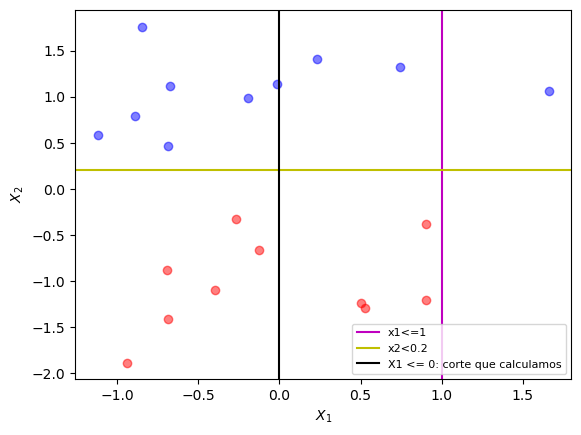

In [2]:
X0, y0 = make_classification(n_samples=20,
    n_features=2, n_redundant=0, n_informative=1, random_state=1, 
    n_clusters_per_class=1)

x=np.arange(-2, 3,1)
x_,y_ = np.meshgrid(x,x)

fig, ax = plt.subplots()
ax.plot(X0[:,0][y0==0],X0[:,1][y0==0],"ro", alpha=0.5)
ax.plot(X0[:,0][y0==1],X0[:,1][y0==1],"bo", alpha=0.5)
#ax.plot(x_,y_,"k.")

ax.axvline(x = 1, color = 'm', label="x1<=1")
ax.axhline(y = 0.2, color = 'y', label="x2<0.2")
ax.axvline(x = 0.0, color = 'k', label="X1 <= 0: corte que calculamos")
ax.legend(fontsize=8)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.show()

## Cálculo de Gini

El corte $X_1\leq0$ deja 13 y 7 muestras. Con las proporciones de clase de cada hijo y pesos 13/20 y 7/20, el Gini ponderado es 45/91, menor que 0.5 del padre.

In [3]:
izquierda = X0[:, 0] <= 0
derecha = ~izquierda
conteos_izq = np.bincount(y0[izquierda], minlength=2)
conteos_der = np.bincount(y0[derecha], minlength=2)
n_izq, n_der = conteos_izq.sum(), conteos_der.sum()
n_total = len(y0)

# Proporciones dentro de cada hijo.
p_izq = conteos_izq / n_izq
p_der = conteos_der / n_der
gini_izq = 1 - np.sum(p_izq**2)
gini_der = 1 - np.sum(p_der**2)

# Pesos de los hijos: 13/20 y 7/20.
peso_izq = n_izq / n_total
peso_der = n_der / n_total
coste_corte = peso_izq*gini_izq + peso_der*gini_der
p_padre = np.bincount(y0, minlength=2) / n_total
gini_padre = 1 - np.sum(p_padre**2)

display(pd.DataFrame({
    'Región': ['X1 <= 0', 'X1 > 0'],
    'Rojos': [conteos_izq[0], conteos_der[0]],
    'Azules': [conteos_izq[1], conteos_der[1]],
    'Muestras': [n_izq, n_der],
    'Peso': [peso_izq, peso_der],
    'Gini': [gini_izq, gini_der],
}))
print(f'Los pesos suman: {peso_izq + peso_der:.2f}')
print(f'Gini del padre: {gini_padre:.6f}')
print(f'Coste ponderado del corte: {coste_corte:.6f}')
print(f'Reducción de impureza: {gini_padre - coste_corte:.6f}')

Los pesos suman: 1.00
Gini del padre: 0.500000
Coste ponderado del corte: 0.494505
Reducción de impureza: 0.005495


,Región,Rojos,Azules,Muestras,Peso,Gini
0,X1 <= 0,6,7,13,0.65,0.497041
1,X1 > 0,4,3,7,0.35,0.489796


## 1. Cargar Iris

Iris tiene 150 flores, cuatro medidas en centímetros y tres especies. X contiene las medidas; y contiene la especie.

In [4]:
iris = load_iris()
X = iris.data
y = iris.target

df_iris = pd.DataFrame(X, columns=iris.feature_names)
df_iris['especie'] = iris.target_names[y]

print('Forma de X (flores, medidas):', X.shape)
print('Forma de y:', y.shape)
print('Etiquetas:', dict(enumerate(iris.target_names)))
display(df_iris.head())

Forma de X (flores, medidas): (150, 4)
Forma de y: (150,)
Etiquetas: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Explorar los datos

Los pétalos separan bien a setosa; versicolor y virginica se superponen más. Reviso rangos, faltantes y flores por especie.

Número de flores por especie:
Valores faltantes por columna:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
especie              0
dtype: int64

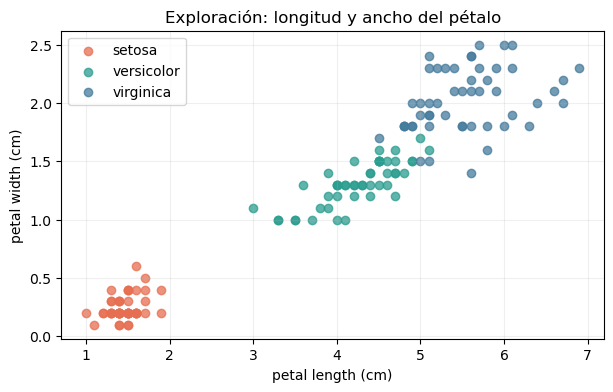

In [5]:
display(df_iris.describe())
print('Número de flores por especie:')
display(df_iris['especie'].value_counts())
print('Valores faltantes por columna:')
display(df_iris.isna().sum())

colores = ['#e76f51', '#2a9d8f', '#457b9d']
fig, ax = plt.subplots(figsize=(7, 4))
for clase, color in enumerate(colores):
    mascara = y == clase
    ax.scatter(X[mascara, 2], X[mascara, 3],
               color=color, label=iris.target_names[clase], alpha=0.75)
ax.set(xlabel=iris.feature_names[2], ylabel=iris.feature_names[3],
       title='Exploración: longitud y ancho del pétalo')
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 3. Separar entrenamiento y prueba

Uso 120 flores para entrenar y 30 para prueba, con 40 y 10 por especie. El árbol usa umbrales, por lo que mantengo las medidas sin estandarizar.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print('Entrenamiento:', X_train.shape, y_train.shape)
print('Prueba:', X_test.shape, y_test.shape)
display(pd.DataFrame({
    'Entrenamiento': np.bincount(y_train, minlength=3),
    'Prueba': np.bincount(y_test, minlength=3),
}, index=iris.target_names))

Entrenamiento: (120, 4) (120,)
Prueba: (30, 4) (30,)


,Entrenamiento,Prueba
setosa,40,10
versicolor,40,10
virginica,40,10


## 4. Entrenar el árbol

Uso Gini y profundidad máxima de tres, fijada antes de evaluar. El árbol principal recibe las cuatro variables.

In [7]:
clf = DecisionTreeClassifier(
    criterion='gini', max_depth=3, random_state=42
)
clf.fit(X_train, y_train)

print('Variables de entrada:', clf.n_features_in_)
print('Profundidad aprendida:', clf.get_depth())
print('Número de hojas:', clf.get_n_leaves())
print('Muestras en la raíz:', clf.tree_.n_node_samples[0])

Variables de entrada: 4
Profundidad aprendida: 3
Número de hojas: 5
Muestras en la raíz: 120


## 5. Leer el árbol

Cada nodo compara una medida con un umbral: si cumple la condición, sigue a la izquierda. La hoja predice su especie mayoritaria. Gini mide la mezcla de clases y samples cuenta las flores de entrenamiento.

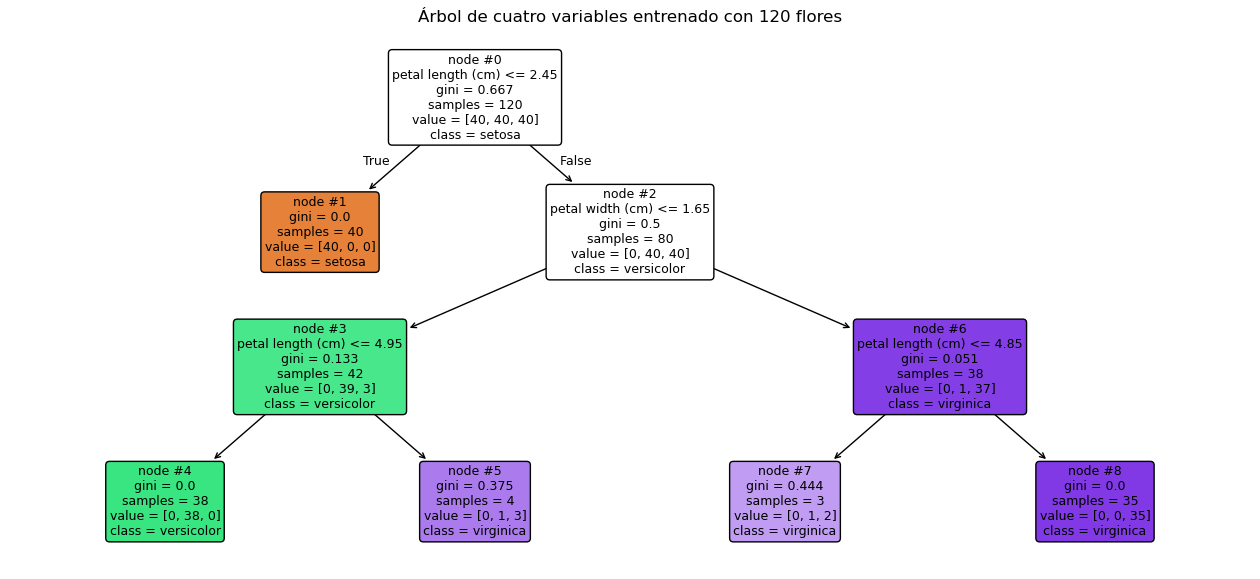

In [8]:
fig, ax = plt.subplots(figsize=(16, 7))
tree.plot_tree(
    clf, feature_names=iris.feature_names, class_names=list(iris.target_names),
    impurity=True, filled=True, rounded=True, node_ids=True, fontsize=9, ax=ax
)
ax.set_title('Árbol de cuatro variables entrenado con 120 flores')
plt.show()

### Recorrido de una flor

Sigo una flor de entrenamiento desde la raíz hasta su hoja y muestro cada comparación.

In [9]:
flor = X_train[[0]]
nodos_visitados = clf.decision_path(flor).indices
hoja = clf.apply(flor)[0]
display(pd.Series(flor[0], index=iris.feature_names, name='Medidas de la flor'))

for nodo in nodos_visitados:
    if nodo == hoja:
        continue
    variable = clf.tree_.feature[nodo]
    umbral = clf.tree_.threshold[nodo]
    valor = flor[0, variable]
    relacion = '<=' if valor <= umbral else '>'
    print(f'Nodo {nodo}: {iris.feature_names[variable]} = {valor:.2f} {relacion} {umbral:.2f}')

prediccion_flor = clf.predict(flor)[0]
print(f'Hoja {hoja}: predicción = {iris.target_names[prediccion_flor]}')
print('Especie real de esta flor:', iris.target_names[y_train[0]])

Nodo 0: petal length (cm) = 1.40 <= 2.45
Hoja 1: predicción = setosa
Especie real de esta flor: setosa


sepal length (cm)    4.4
sepal width (cm)     2.9
petal length (cm)    1.4
petal width (cm)     0.2
Name: Medidas de la flor, dtype: float64

## 6. Importancia de las características

La importancia mide la reducción de Gini de cada variable. Cero indica que el árbol no la usó. En esta partición destacan los pétalos.

,Importancia
petal length (cm),0.579077
petal width (cm),0.420923
sepal width (cm),0.000000
sepal length (cm),0.000000


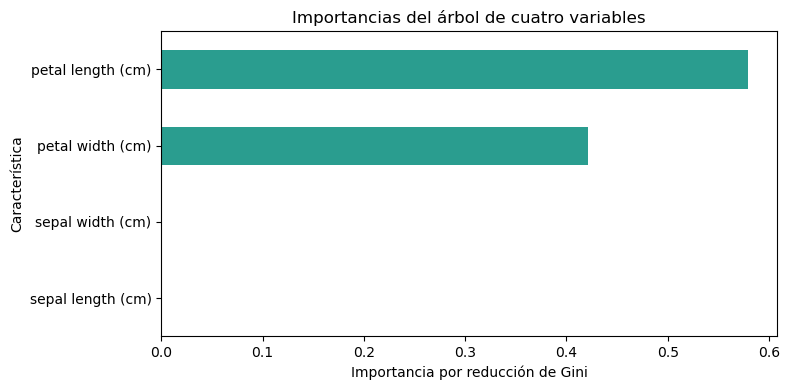

In [10]:
importancias = pd.Series(
    clf.feature_importances_, index=iris.feature_names, name='Importancia'
).sort_values(ascending=False)
display(importancias.to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
importancias.sort_values().plot.barh(ax=ax, color='#2a9d8f')
ax.set(xlabel='Importancia por reducción de Gini', ylabel='Característica',
       title='Importancias del árbol de cuatro variables')
plt.tight_layout()
plt.show()

## 7. Fronteras de decisión

Entreno un árbol por cada uno de los seis pares de medidas. Son modelos distintos al principal. Sus cortes se alinean con los ejes; los pétalos separan mejor a setosa que los sépalos.

El modelo principal sigue esperando 4 características.


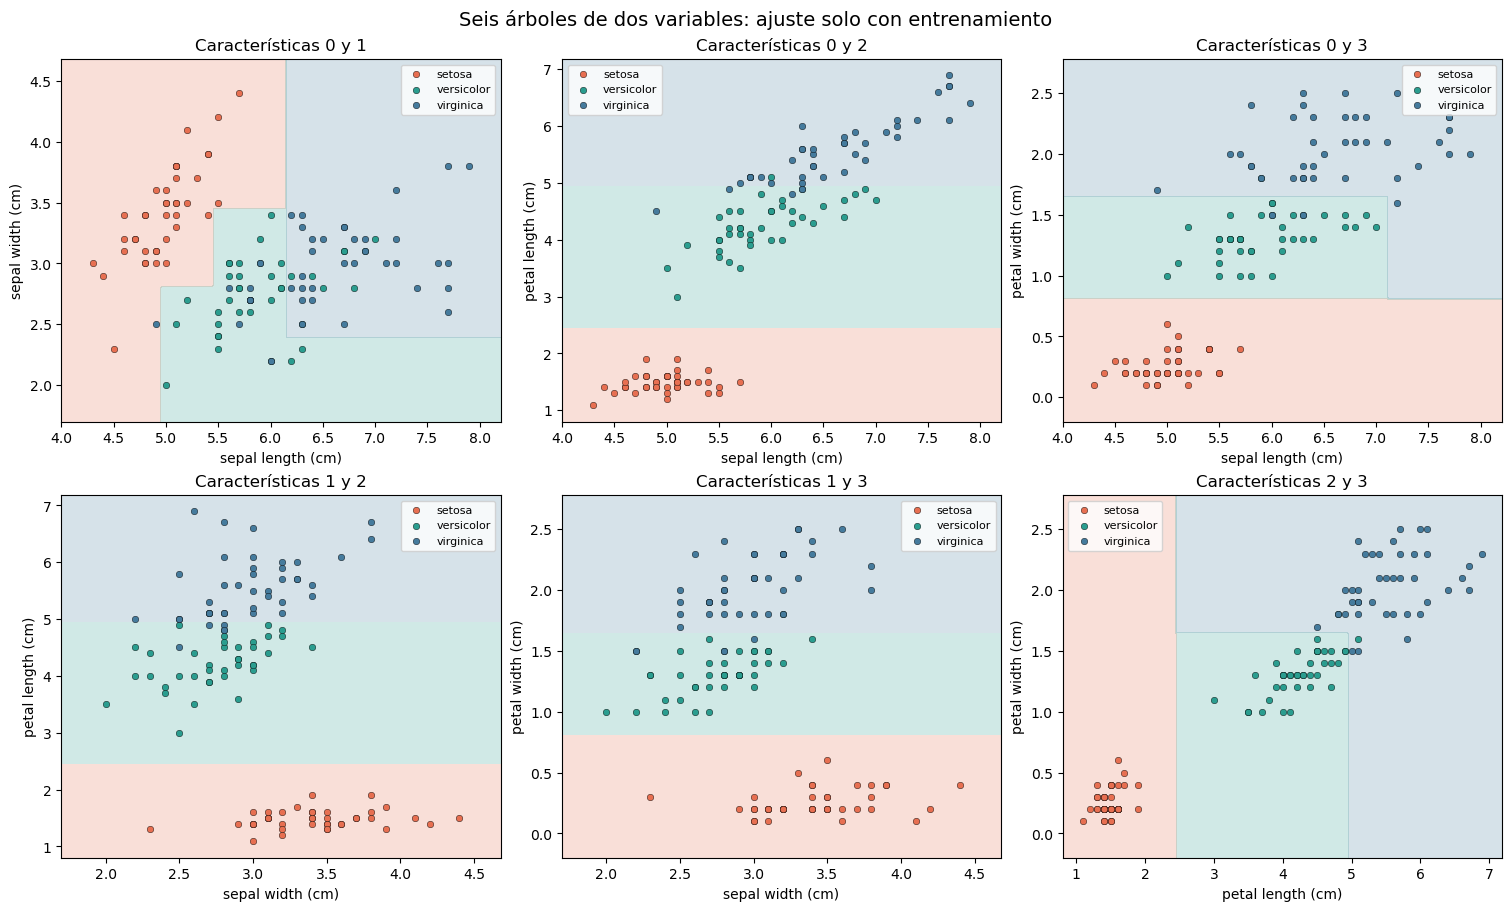

In [11]:
pares = list(combinations(range(4), 2))
modelos_por_par = {}
fig, ejes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)

for ax, par in zip(ejes.ravel(), pares):
    X_train_par = X_train[:, par]
    clf_2d = DecisionTreeClassifier(max_depth=3, criterion='gini', random_state=42)
    clf_2d.fit(X_train_par, y_train)
    modelos_por_par[par] = clf_2d

    x_min, x_max = X_train_par[:, 0].min() - 0.3, X_train_par[:, 0].max() + 0.3
    y_min, y_max = X_train_par[:, 1].min() - 0.3, X_train_par[:, 1].max() + 0.3
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02)
    )
    puntos_malla = np.c_[xx.ravel(), yy.ravel()]
    regiones = clf_2d.predict(puntos_malla).reshape(xx.shape)
    ax.contourf(xx, yy, regiones, levels=[-0.5, 0.5, 1.5, 2.5],
                colors=colores, alpha=0.22)

    for clase, color in enumerate(colores):
        mascara = y_train == clase
        ax.scatter(X_train_par[mascara, 0], X_train_par[mascara, 1],
                   color=color, edgecolor='black', linewidth=0.3, s=22,
                   label=iris.target_names[clase])
    ax.set(xlabel=iris.feature_names[par[0]], ylabel=iris.feature_names[par[1]],
           title=f'Características {par[0]} y {par[1]}')
    ax.legend(fontsize=8)

fig.suptitle('Seis árboles de dos variables: ajuste solo con entrenamiento', fontsize=14)
plt.show()
print('El modelo principal sigue esperando', clf.n_features_in_, 'características.')

## Evaluación

La matriz usa especies reales en las filas y predicciones en las columnas. Cada error en las 30 flores de prueba cambia el acierto en 3.33 puntos porcentuales.

Accuracy de entrenamiento: 0.983
Accuracy de prueba: 0.967 (29/30 flores)

Reporte por especie:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



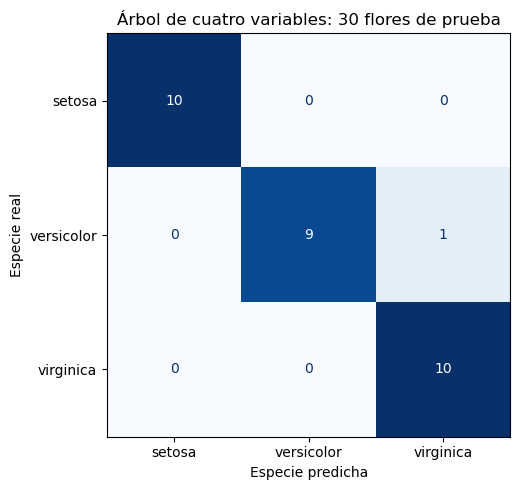

In [12]:
y_pred_train = clf.predict(X_train)
y_pred_test = clf.predict(X_test)
accuracy_train = accuracy_score(y_train, y_pred_train)
accuracy_test = accuracy_score(y_test, y_pred_test)
aciertos = int(np.sum(y_pred_test == y_test))

print(f'Accuracy de entrenamiento: {accuracy_train:.3f}')
print(f'Accuracy de prueba: {accuracy_test:.3f} ({aciertos}/{len(y_test)} flores)')
print()
print('Reporte por especie:')
print(classification_report(y_test, y_pred_test, labels=[0, 1, 2],
                            target_names=list(iris.target_names), zero_division=0))

matriz_confusion = confusion_matrix(y_test, y_pred_test, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matriz_confusion, display_labels=iris.target_names).plot(
    ax=ax, cmap='Blues', colorbar=False
)
ax.set(xlabel='Especie predicha', ylabel='Especie real',
       title='Árbol de cuatro variables: 30 flores de prueba')
plt.tight_layout()
plt.show()

## Comprobaciones

Compruebo las dimensiones, las seis parejas de variables y el conteo de las 30 flores de prueba.

In [13]:
assert X.shape == (150, 4) and y.shape == (150,)
assert X_train.shape == (120, 4) and X_test.shape == (30, 4)
assert np.array_equal(np.bincount(y_train), [40, 40, 40])
assert np.array_equal(np.bincount(y_test), [10, 10, 10])
assert clf.n_features_in_ == 4
assert clf.tree_.n_node_samples[0] == len(X_train)
assert len(modelos_por_par) == 6
assert all(modelo.n_features_in_ == 2 for modelo in modelos_por_par.values())
assert np.isclose(clf.feature_importances_.sum(), 1)
assert matriz_confusion.sum() == len(y_test)
assert y_pred_test.shape == y_test.shape
assert 0 <= accuracy_test <= 1
assert (n_izq, n_der) == (13, 7)
assert np.isclose(peso_izq, 13/20) and np.isclose(peso_der, 7/20)
assert np.isclose(peso_izq + peso_der, 1)
assert np.isclose(coste_corte, 45/91)
assert coste_corte <= gini_padre
print('Comprobaciones correctas: Gini, pesos, partición, dimensiones y predicciones.')

Comprobaciones correctas: Gini, pesos, partición, dimensiones y predicciones.


In [14]:
raiz = clf.tree_.feature[0]
print(f'Primer corte: {iris.feature_names[raiz]} <= {clf.tree_.threshold[0]:.2f} cm.')
print(f'Mayor importancia: {importancias.index[0]} ({importancias.iloc[0]:.3f}).')
print(f'La prueba tuvo {aciertos} aciertos y {len(y_test)-aciertos} errores.')
for real, predicha in zip(*np.where(matriz_confusion - np.diag(np.diag(matriz_confusion)) > 0)):
    print(f'{iris.target_names[real]} se confundió con {iris.target_names[predicha]}: '
          f'{matriz_confusion[real, predicha]} flores.')

Primer corte: petal length (cm) <= 2.45 cm.
Mayor importancia: petal length (cm) (0.579).
La prueba tuvo 29 aciertos y 1 errores.
versicolor se confundió con virginica: 1 flores.
